# User-defined visibility model

FRAP assumes thermal emission from dust grains by default. However, sometimes this assumption is not valid, especially at the disc ceneter, where the free-free gas emission can be observed. To treat this, we can include user-defined visibility model in addition to the gaussian process-based model.

We use the HD 169142 ALMA Band 3 and Band 6 data as used in [Retrieving dust properties](tutorial_1.ipynb) and add a compact free-free component to the disk model. Put `HD169142_band3.pkl` and `HD169142_band6.pkl` in the notebook directory.

In [1]:
import frap
import pickle
import numpy as np
import jax.numpy as jnp
import dsharp_opac
import matplotlib.pyplot as plt

bands = ['band3', 'band6']
files = {'band3': 'HD169142_band3.pkl',
         'band6': 'HD169142_band6.pkl'}

obs = {}
for band in bands:
    with open(files[band], 'rb') as f:
        obs[band] = pickle.load(f)

dust_opacity = jnp.load(dsharp_opac.get_datafile('default_opacities_smooth.npz'))

## 1. Define an additional visibility component

`userdef_vis_model(V, obs, p)` receives the disk visibility in Jy. Here a point source is added, with an illustrative spectral index of 0.6. Here, the user defined function should take input as below. `obs` has values related to the observations and we can directly access them.

In [2]:
def add_freefree(V, obs, p):
    
    # Unresolved point source: its visibility is independent of baseline.
    # We'll sample the flux at 100 GHz (in mJy)
    S_ff = 10**p['log10Sff100'] * (obs.nu / 33e9)**0.6  / 1e3
    
    return V + S_ff

## 2. Set the model

We use the same disk geometry, opacity and ALMA observations as Tutorial 1. Now we also include the visibility model to `userdef_vis_model`.
In the `set_parameter()` function, you can now define the parameter you want to put to your function. `GP` should be set to False, and `mean_std` is a tuple of the mean and standard deviation of the gaussian prior.

In [3]:
disk = frap.model(incl=6.28, 
                  pa=6.3, 
                  r_out=1.3, 
                  N_GP=130,
                  userdef_vis_model=add_freefree)

# others are the same as before
disk.set_parameter('log10_T', free=False, profile=lambda r: jnp.log10(77.0 * (r * 114.9 / 10)**(-0.5)))
disk.set_parameter('q', free=False, profile=3.5)
disk.set_parameter('log10_Sigma_d', bounds=(-6.0, 3.0), lengthscale=0.03)
disk.set_parameter('log10_a_max', bounds=(-2.0, 2.0), lengthscale=0.03)

# now you define this
disk.set_parameter('log10Sff100', 
                   GP=False, 
                   mean_std=(-1.0, 3.0))

f_s = {'band3': 0.025, 'band6': 0.05}
for band in bands:
    disk.set_visibility(band=band, 
                        q=obs[band]['q'], 
                        V=obs[band]['V'], 
                        s=obs[band]['s'], 
                        nu=obs[band]['nu'], 
                        Nch=obs[band]['Nch'], 
                        f_s=f_s[band],
                        f_mean=1.0)

disk.set_opacity(dust_opacity)


Then you can see summary of your model.

In [4]:
disk.summary()

FRAP model summary

[Model]
  Inclination      : 6.280 deg
  Position angle   : 6.300 deg
  Radial grid      : FB, N=130, r_out=1.3 arcsec
  Radial range     : 0.007611 - 1.29 arcsec
  Jitter           : 0.0001
  GP hyperparams   : fixed
  Flux uncertainty : True

[Emission]
  Intensity  : f_I_SL20
  Visibility : add_freefree
  Opacity    : configured (Na=1000, Nq=1000, smooth=True)

[Parameters]  3 free, 2 fixed, 261 latent variables
  log10_Sigma_d     : GP, bounds=(-6, 3), lengthscale=0.03 arcsec
  log10_a_max       : GP, bounds=(-2, 2), lengthscale=0.03 arcsec
  log10Sff100       : Normal(mean=-1, std=3)
  log10_T           : fixed, shape=(130,), range=[1.301, 2.416]
  q                 : fixed, 3.5

[Observations]
  Band   Type        Nch  Frequency [GHz]       Ndata
  band3  visibility    2  91.565-103.565          257
  band6  visibility    4  218.096-234.096         948


'FRAP model summary\n==================\n\n[Model]\n  Inclination      : 6.280 deg\n  Position angle   : 6.300 deg\n  Radial grid      : FB, N=130, r_out=1.3 arcsec\n  Radial range     : 0.007611 - 1.29 arcsec\n  Jitter           : 0.0001\n  GP hyperparams   : fixed\n  Flux uncertainty : True\n\n[Emission]\n  Intensity  : f_I_SL20\n  Visibility : add_freefree\n  Opacity    : configured (Na=1000, Nq=1000, smooth=True)\n\n[Parameters]  3 free, 2 fixed, 261 latent variables\n  log10_Sigma_d     : GP, bounds=(-6, 3), lengthscale=0.03 arcsec\n  log10_a_max       : GP, bounds=(-2, 2), lengthscale=0.03 arcsec\n  log10Sff100       : Normal(mean=-1, std=3)\n  log10_T           : fixed, shape=(130,), range=[1.301, 2.416]\n  q                 : fixed, 3.5\n\n[Observations]\n  Band   Type        Nch  Frequency [GHz]       Ndata\n  band3  visibility    2  91.565-103.565          257\n  band6  visibility    4  218.096-234.096         948'

## 3. Run MCMC

Fit the disk and free-free flux simultaneously. Note that the number of samples here is just for demonstration and maybe too small to reach convergence.

In [5]:
inference = frap.inference(disk)
result = inference.MCMC(num_warmup=500, num_samples=1000, num_chains=1, seed=1)

sample: 100%|██████████████████████████| 1000/1000 [02:33<00:00,  6.50it/s, 1023 steps of size 1.81e-02. acc. prob=0.96]



                            mean       std    median      5.0%     95.0%     n_eff     r_hat
       g_f_scale_band3     10.19      0.24     10.19      9.78     10.60     63.49      1.08
       g_f_scale_band6      6.42      0.10      6.42      6.24      6.57     72.49      1.07
         g_log10Sff100     -0.02      0.00     -0.02     -0.03     -0.02    979.38      1.00
  g_log10_Sigma_d_z[0]     -1.02      0.36     -0.98     -1.54     -0.43    253.13      1.03
  g_log10_Sigma_d_z[1]      0.96      0.53      0.92      0.08      1.79    101.43      1.01
  g_log10_Sigma_d_z[2]     -0.36      0.63     -0.35     -1.37      0.67     62.17      1.01
  g_log10_Sigma_d_z[3]     -0.73      0.72     -0.71     -1.84      0.58     14.94      1.17
  g_log10_Sigma_d_z[4]     -0.55      0.95     -0.52     -2.14      0.89     11.04      1.11
  g_log10_Sigma_d_z[5]     -0.88      0.83     -0.89     -2.16      0.53     52.77      1.04
  g_log10_Sigma_d_z[6]     -0.84      0.92     -0.90     -2.22      0

## 4. Inspect the results

saved keys:  dict_keys(['warmup_f', 'posterior_f', 'warmup_g', 'posterior_g'])


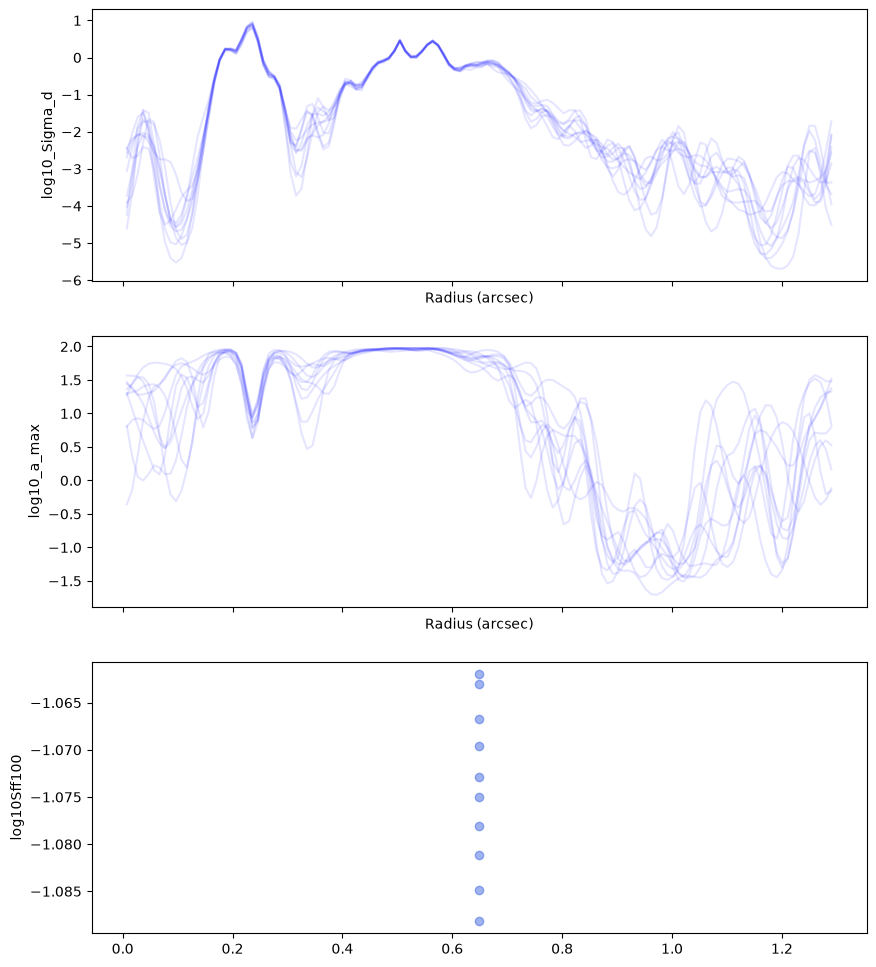

In [8]:
plotter = frap.plot( result )
plotter.sample_paths( 'posterior_f', nskip = 100, plot_kwargs = { 'alpha' : 0.1, 'color' : 'b' } )

## 4. Posterior distribution of the free-free flux

You can also see the posterior of the free-free flux. The median is ~0.084 mJy, which is close to the image-base inner disk flux at 97 GHz, 0.090 ± 0.011 (Rota et al. 2024).

S_ff (100 GHz) = 0.0844 +0.0016 -0.0017 mJy


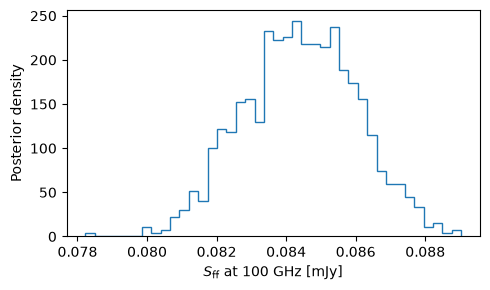

In [12]:

log10Sff100 = (result.sample['posterior_f']['log10Sff100']).reshape(-1)

S_ff = 10**log10Sff100  # mJy at 100 GHz

p16, p50, p84 = np.percentile(S_ff, [16, 50, 84])
print(f'S_ff (100 GHz) = {p50:.4f} +{p84-p50:.4f} -{p50-p16:.4f} mJy')

plt.figure(figsize=(5, 3))
plt.hist(S_ff, bins=40, density=True, histtype='step')

plt.xlabel(r'$S_{\rm ff}$ at 100 GHz [mJy]')
plt.ylabel('Posterior density')
plt.tight_layout()